Solve for the function $y$ that satsifies the governing equation

$$ 4 \pi\frac{\partial y}{\partial t} + \frac{\partial y}{\partial x} = \sin\left(\frac{xt}{\pi}\right) $$

with the boundary condition

$$ y(t,-1) = 1 $$

and initial condition

$$ y(0,x) = -1 $$

on the domain $-1 \le x \le 1$ and for $ t \le 40$.

Sample output (for different initial conditions) is included below.

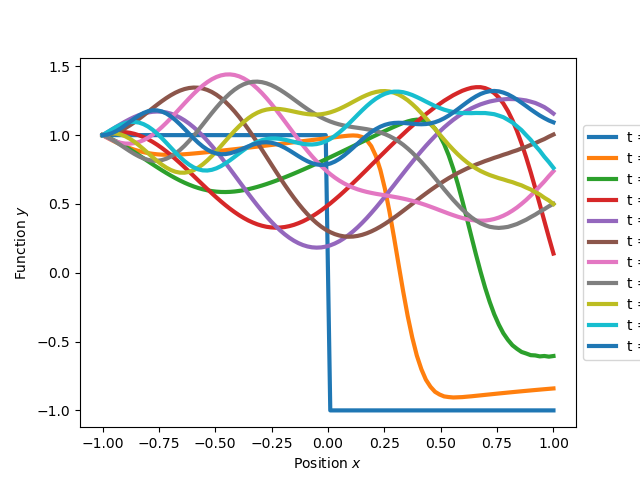

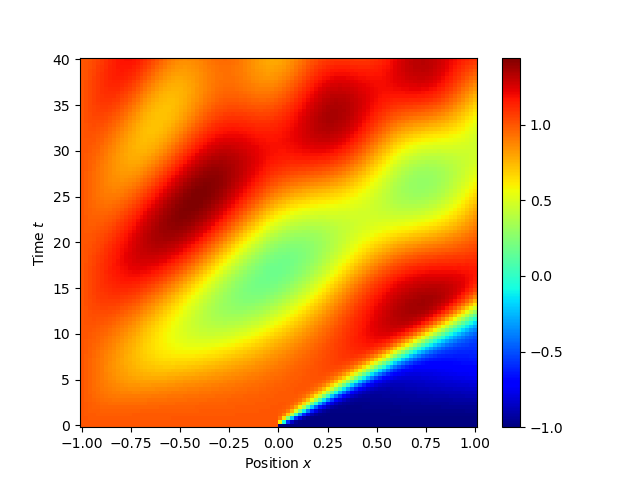

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as intx
from mpl_toolkits.mplot3d import Axes3D

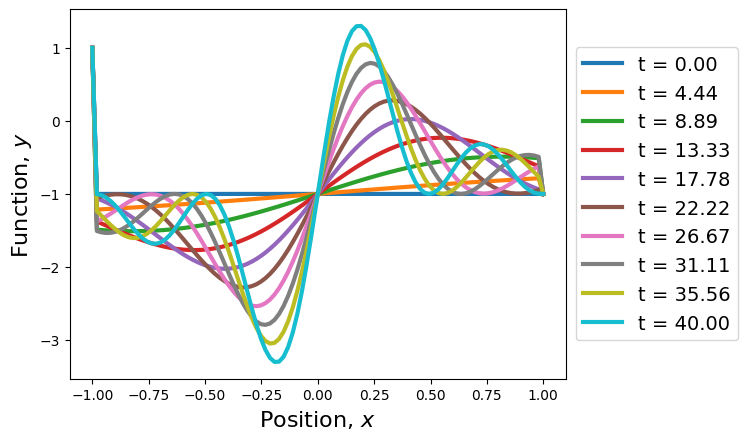

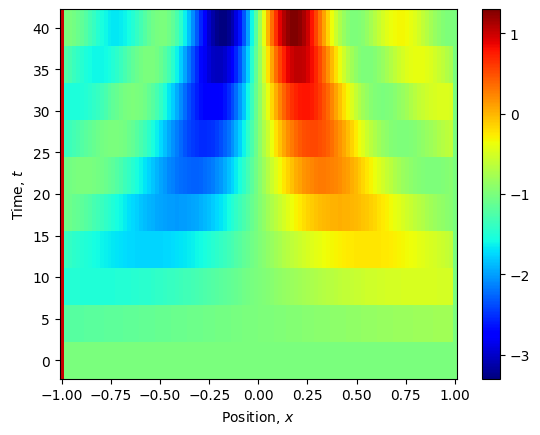

In [ ]:
# first order with respective to time and x position

#boundary conditions 

x_left = -1
y_left = 1

# discretize space
x_right = 1
Nx = 100
x = np.linspace(x_left,x_right,Nx)
dx = x[1]-x[0]

#discretize time
Nt = 10
ti,tf = 0,40
t = np.linspace(ti,tf,Nt)

# define functions
def pde(t,v):
    y = v

    dydt = np.zeros_like(y)
    dydx = np.zeros_like(y)

    # interior boundary

    for i in range(1,Nx-1):
       # dydx[i]=(y[i+1]-y[i])/dx     ## could not get this part to work ##
        dydt[i] = (1/(4*np.pi))*(np.sin(x[i]*t/np.pi) - (dydx[i]))
    
    # left boundary condition
    dydt[0] = 0
    return dydt
    
# main code
y0 = -1*np.ones(Nx)
y0[0]= y_left # boundary condition

# solve ode
y = intx.solve_ivp(pde,(ti,tf),y0,t_eval=t).y # function, time span, intitial value (y0), time range

#plot solution
for it,ti in enumerate(t):
    plt.plot(x,y[:,it], lw=3,label='t = %.2f' % ti)
    plt.legend(fontsize =14, loc = 'center left',bbox_to_anchor=(1,0.5))
    plt.xlabel('Position, $x$',fontsize =16)
    plt.ylabel('Function, $y$', fontsize =16)

plt.show()

plt.pcolormesh(x,t,y.T,cmap ='jet',shading='auto')
cb = plt.colorbar()
cb.ax.tick_params(labelsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.xlabel('Position, $x$', fontsize = 10)
plt.ylabel('Time, $t$', fontsize=10)
plt.show()

